In [1]:
import logging, warnings
warnings.filterwarnings("ignore")
logging.getLogger("torch.distributed.elastic").setLevel(logging.ERROR)
import torch, transformers
transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
print("Name: Thanh Trinh")
print("torch version:", torch.__version__)
print("transformers version:", transformers.__version__)

Name: Thanh Trinh
torch version: 2.15.0
transformers version: 5.22.2


# CSE 256 PA2, Part 3: Dissecting a Pretrained LLM

Model: `EleutherAI/pythia-160m-deduped` (12 layers, 12 heads, d = 768). `transformers` is used only to load the model and tokenizer; all lens and transplant code is my own.

In [2]:
import gc
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from transformers import AutoTokenizer, GPTNeoXForCausalLM

torch.manual_seed(0)
torch.set_grad_enabled(False)
NAME = "EleutherAI/pythia-160m-deduped"
tok = AutoTokenizer.from_pretrained(NAME)


def load(revision):
    return GPTNeoXForCausalLM.from_pretrained(NAME, revision=revision, torch_dtype=torch.float32).eval()


with open("speechesdataset/test_LM_obama.txt", encoding="utf-8") as f:
    obama_ids = tok(f.read(), return_tensors="pt").input_ids[0]
CHUNK = 512
chunks = [obama_ids[i:i + CHUNK] for i in range(0, len(obama_ids), CHUNK)]
chunks = [c for c in chunks if len(c) > 1]
n_targets = sum(len(c) - 1 for c in chunks)
print(f"test_LM_obama.txt: {len(obama_ids)} tokens in {len(chunks)} chunks of up to {CHUNK}; {n_targets} next-token targets")

test_LM_obama.txt: 6017 tokens in 12 chunks of up to 512; 6005 next-token targets


## 3.1 Reading Pythia

**1. Why checkpoints?**

The three case studies are in Section 3 of Biderman et al.: data bias (§3.1), training order and memorization (§3.2), and term frequency (§3.3).

- **Depends most on the design: the gender-bias intervention (§3.1).** The authors take a checkpoint *and its optimizer state* 21B tokens (7%) before the end of training and resume training on *exactly the same data in the same order*, with only masculine pronouns swapped for feminine ones. The paper states that without resuming "on the exact same data in the exact same order" they could not be sure they were measuring only the effect of pronoun frequency. This needs intermediate checkpoints and the fixed, reproducible data order together.
- **Also needs checkpoints: term frequency (§3.3).** It asks *when* during training few-shot accuracy starts to depend on term frequency, so it evaluates many checkpoints and counts term frequencies in exactly the data each checkpoint has seen.
- **Could mostly be done with the final model: memorization (§3.2).** It measures (32, 32)-memorization of training sequences and asks whether sequences seen later are memorized more (they are not; a Poisson process fits). That needs the known data order, to place each sequence in time, but can be measured on the final model alone (Figure 3 uses the final 12B model), not on intermediate checkpoints.

**2. Data.**

Section 2.6 ("Novel Observations in Evaluation") reports that **deduplicating the training data has no clear benefit on language modeling performance**: the deduped and standard Pythia models perform about the same on the benchmarks (plots in Appendix G). This is consistent with Black et al. (2022) but runs against the common claim that deduplicated data gives better models; the authors suggest it may reflect how the Pile upsamples some subsets, or that earlier gains came from data quality. Relatedly, §2.4 notes the deduped models train for about 1.5 epochs on the 207B-token deduplicated Pile, and the second epoch shows no sign of hurting evaluation scores.

## 3.2 The Logit Lens

First, check whether the last entry of `out.hidden_states` already has the final layer norm applied, by comparing both possible readouts against `out.logits`.

In [3]:
final = load("step143000")
W_U = final.get_output_embeddings()
ln_f = final.gpt_neox.final_layer_norm
x = tok("They have not served a Red America or a Blue America", return_tensors="pt").input_ids
out = final(x, output_hidden_states=True)
print("number of hidden states:", len(out.hidden_states), "(embeddings + 12 layers)")
err_raw = (W_U(out.hidden_states[-1]) - out.logits).abs().max().item()
err_ln = (W_U(ln_f(out.hidden_states[-1])) - out.logits).abs().max().item()
print(f"max |W_U(h_12) - logits|        = {err_raw:.2e}")
print(f"max |W_U(LN_f(h_12)) - logits|  = {err_ln:.2e}")
LAST_NORMED = err_raw < err_ln
print("Last hidden state already has LN_f applied:", LAST_NORMED)


def lens_logits(model, h, layer):
    """Logit-lens readout W_U LN_f(h) of hidden state h after `layer` (0 = embeddings)."""
    if layer == model.config.num_hidden_layers and LAST_NORMED:
        return model.get_output_embeddings()(h)
    return model.get_output_embeddings()(model.gpt_neox.final_layer_norm(h))

number of hidden states: 13 (embeddings + 12 layers)
max |W_U(h_12) - logits|        = 0.00e+00
max |W_U(LN_f(h_12)) - logits|  = 1.75e+01
Last hidden state already has LN_f applied: True


### 3.2.1 Watch a prediction form

Each cell shows the lens's top-1 token at that layer and position; the shade is the probability the lens assigns to the true next token (the last position has no next token, so it is unshaded).

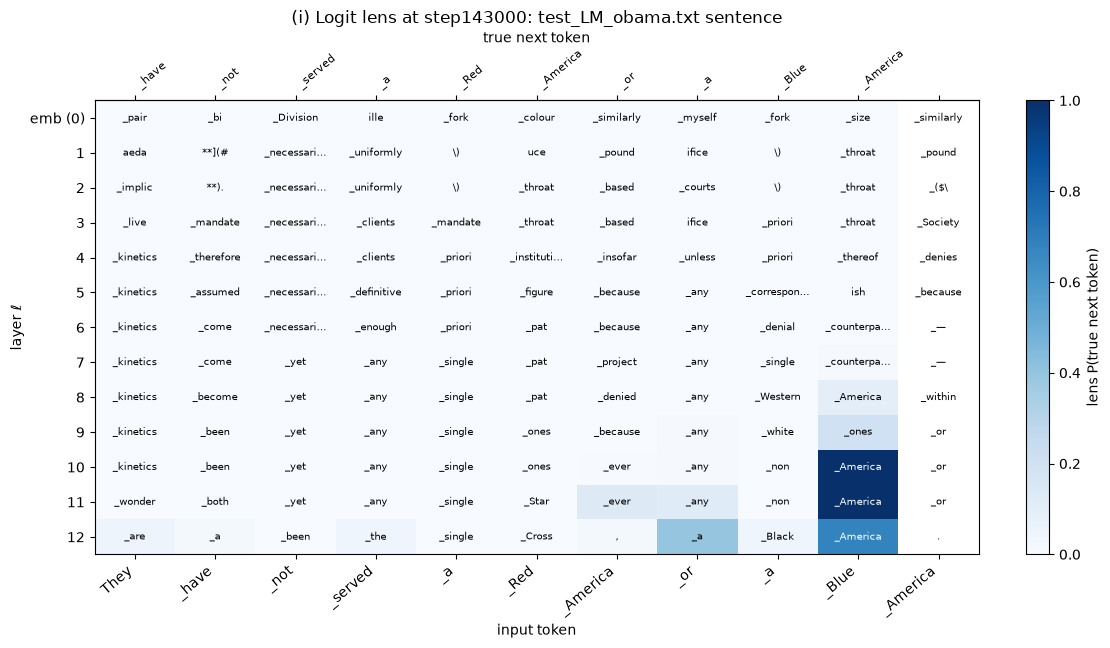

final-layer top-1 per position: ['_are', '_a', '_been', '_the', '_single', '_Cross', ',', '_a', '_Black', '_America']
mean P(true next token) at layer 0 / 6 / 12: 0.000 / 0.000 / 0.124


In [4]:
def show(t, width=11):
    t = t.replace(" ", "_").replace("\n", "\\n")
    return t if len(t) <= width else t[:width - 1] + "…"


def lens_grid(model, text, title):
    x = tok(text, return_tensors="pt").input_ids
    hs = model(x, output_hidden_states=True).hidden_states
    T, L = x.shape[1], len(hs)
    top = np.empty((L, T), dtype=object)
    prob = np.full((L, T), np.nan)
    for layer, h in enumerate(hs):
        p = lens_logits(model, h[0], layer).softmax(-1)
        best = p.argmax(-1)
        for i in range(T):
            top[layer, i] = show(tok.decode([best[i]]))
            if i < T - 1:
                prob[layer, i] = p[i, x[0, i + 1]].item()

    inputs = [show(tok.decode([t])) for t in x[0]]
    fig, ax = plt.subplots(figsize=(0.82 * T + 2.2, 0.36 * L + 1.9))
    im = ax.imshow(prob, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    for layer in range(L):
        for i in range(T):
            dark = not np.isnan(prob[layer, i]) and prob[layer, i] > 0.55
            ax.text(i, layer, top[layer, i], ha="center", va="center", fontsize=7,
                    color="white" if dark else "black")
    ax.set_xticks(range(T))
    ax.set_xticklabels(inputs, rotation=40, ha="right")
    ax.set_yticks(range(L))
    ax.set_yticklabels(["emb (0)"] + [str(l) for l in range(1, L)])
    ax.set_xlabel("input token")
    ax.set_ylabel("layer ℓ")
    top_ax = ax.secondary_xaxis("top")
    top_ax.set_xticks(range(T))
    top_ax.set_xticklabels([show(tok.decode([t])) for t in x[0, 1:]] + [""], rotation=40, ha="left", fontsize=8)
    top_ax.set_xlabel("true next token")
    fig.colorbar(im, ax=ax, label="lens P(true next token)", fraction=0.025)
    ax.set_title(title)
    fig.tight_layout()
    plt.show()
    real = top[-1, :-1]
    print("final-layer top-1 per position:", list(real))
    print(f"mean P(true next token) at layer 0 / 6 / 12: "
          f"{np.nanmean(prob[0]):.3f} / {np.nanmean(prob[6]):.3f} / {np.nanmean(prob[12]):.3f}")


lens_grid(final, "They have not served a Red America or a Blue America",
          "(i) Logit lens at step143000: test_LM_obama.txt sentence")

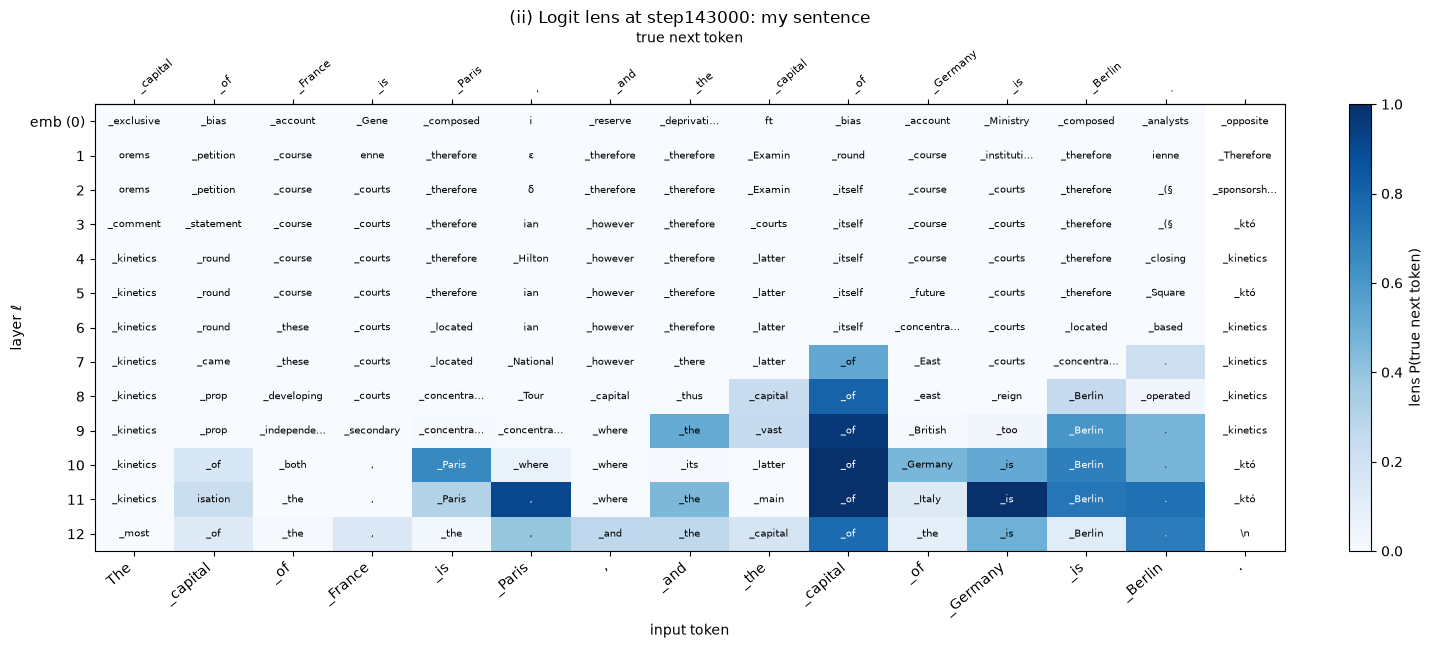

final-layer top-1 per position: ['_most', '_of', '_the', ',', '_the', ',', '_and', '_the', '_capital', '_of', '_the', '_is', '_Berlin', '.']
mean P(true next token) at layer 0 / 6 / 12: 0.000 / 0.000 / 0.255


In [5]:
lens_grid(final, "The capital of France is Paris, and the capital of Germany is Berlin.",
          "(ii) Logit lens at step143000: my sentence")

**What the grids show.**

- **The early and middle layers are unreadable.** From the embeddings up to about layer 7, the lens's top tokens are unrelated to the context and often repeat down a column regardless of the input (`_kinetics` at the first position from layer 4 to 10 in both sentences, `_necessarily` above `not` from layer 1 to 6, `_therefore` and `_courts` throughout sentence (ii)). The printed mean probability of the true next token is 0.000 at layers 0 and 6 for both sentences.
- **Predictions form in the last few layers.** In (i), the lens first ranks `_America` after `_Blue` at layer 8; its probability rises to nearly 1 at layers 10 and 11. In (ii), `_of` after the second `_capital` appears at layer 7 and is nearly certain by layer 9, and `_Berlin` after `_is` appears at layer 8 and stays top-1 through layer 12.
- **The last layer often softens or changes what layers 10–11 decided.** In (i), `_America` is darker at layers 10–11 than at layer 12. In (ii), `_Paris` is the lens's top-1 after `France is` at layers 10 and 11, but the real output (layer 12) switches to `_the`. The final layer spreads probability across more continuations instead of committing to one.
- Mean probability of the true next token at layer 12 is 0.124 for (i) and 0.255 for (ii): the factual pattern in my sentence is easier to predict than the political phrase.

Top-1 accuracy of the lens for the true next token, over all of `test_LM_obama.txt`, at every layer (0 = embeddings, then each of the 12 layers).

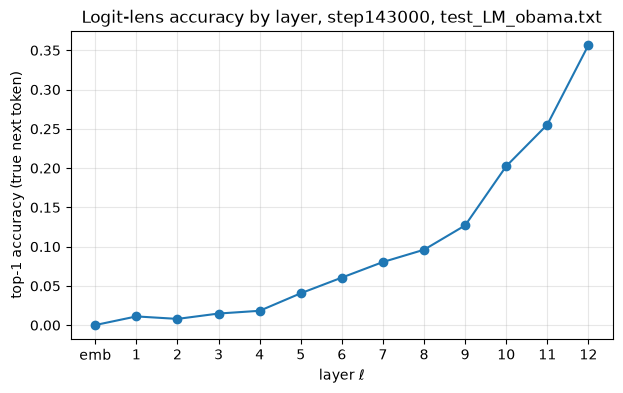

layer  0: accuracy = 0.0002
layer  6: accuracy = 0.0606
layer 12: accuracy = 0.3567


In [6]:
def lens_accuracy(model):
    n_layers = model.config.num_hidden_layers + 1
    correct = torch.zeros(n_layers)
    for c in chunks:
        hs = model(c[None], output_hidden_states=True).hidden_states
        target = c[1:]
        for layer, h in enumerate(hs):
            correct[layer] += (lens_logits(model, h[0, :-1], layer).argmax(-1) == target).sum()
    return (correct / n_targets).numpy()


acc = {"step143000": lens_accuracy(final)}
plt.figure(figsize=(7, 4))
plt.plot(range(13), acc["step143000"], marker="o")
plt.xticks(range(13), ["emb"] + [str(l) for l in range(1, 13)])
plt.xlabel("layer ℓ")
plt.ylabel("top-1 accuracy (true next token)")
plt.title("Logit-lens accuracy by layer, step143000, test_LM_obama.txt")
plt.grid(alpha=0.3)
plt.show()
for layer in (0, 6, 12):
    print(f"layer {layer:2d}: accuracy = {acc['step143000'][layer]:.4f}")

**Accuracy by layer at step143000.** The lens is almost never right at the embeddings (0.0002) and stays below 2% through layer 4. It reaches only 0.061 at layer 6, then climbs steeply over the last layers (0.127 at layer 9, 0.203 at layer 10, 0.256 at layer 11) to the model's real accuracy of 0.357 at layer 12. As in the grids, most of the readable prediction appears in the last three or four layers.

### 3.2.2 Across training

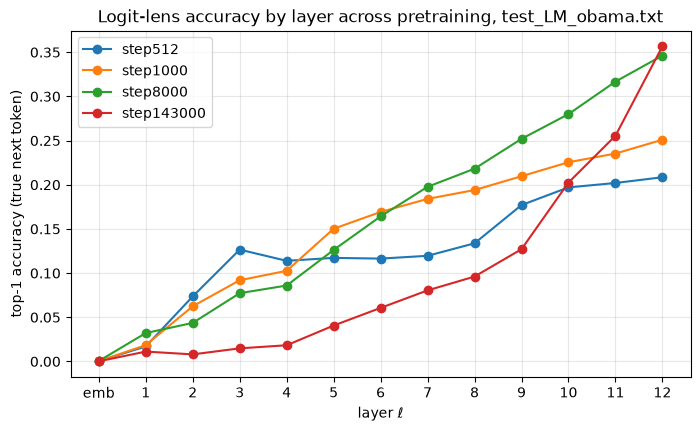

layer        step512    step1000    step8000  step143000
  emb         0.0005      0.0003      0.0005      0.0002
    1         0.0170      0.0185      0.0321      0.0112
    2         0.0736      0.0624      0.0436      0.0080
    3         0.1266      0.0919      0.0773      0.0148
    4         0.1139      0.1026      0.0859      0.0183
    5         0.1172      0.1502      0.1262      0.0406
    6         0.1164      0.1692      0.1642      0.0606
    7         0.1196      0.1840      0.1977      0.0804
    8         0.1337      0.1940      0.2182      0.0961
    9         0.1770      0.2097      0.2520      0.1271
   10         0.1970      0.2255      0.2799      0.2025
   11         0.2020      0.2353      0.3167      0.2555
   12         0.2085      0.2510      0.3462      0.3567

accuracy gap between layer 12 and the best middle layer (4-8):
     step512: final 0.2085, best middle 0.1337, middle/final ratio 0.64
    step1000: final 0.2510, best middle 0.1940, middle/final ratio

In [7]:
for rev in ["step512", "step1000", "step8000"]:
    model = load(rev)
    acc[rev] = lens_accuracy(model)
    del model
    gc.collect()

order = ["step512", "step1000", "step8000", "step143000"]
plt.figure(figsize=(8, 4.5))
for rev in order:
    plt.plot(range(13), acc[rev], marker="o", label=rev)
plt.xticks(range(13), ["emb"] + [str(l) for l in range(1, 13)])
plt.xlabel("layer ℓ")
plt.ylabel("top-1 accuracy (true next token)")
plt.title("Logit-lens accuracy by layer across pretraining, test_LM_obama.txt")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("layer   " + "".join(f"{rev:>12s}" for rev in order))
for layer in range(13):
    print(f"{'emb' if layer == 0 else layer:>5}   " + "".join(f"{acc[rev][layer]:12.4f}" for rev in order))
print("\naccuracy gap between layer 12 and the best middle layer (4-8):")
for rev in order:
    print(f"  {rev:>10s}: final {acc[rev][12]:.4f}, best middle {acc[rev][4:9].max():.4f}, "
          f"middle/final ratio {acc[rev][4:9].max() / acc[rev][12]:.2f}")

**Do the middle layers become more or less readable? Less readable, while the output improves.**

- **Early checkpoints are readable in the middle.** At step512, layer 3 already reaches 0.127 accuracy, 61% of that checkpoint's final-layer accuracy (0.209). At step1000 and step8000 the curves rise steadily through the network, and the best middle layer (4–8) reaches 77% and 63% of the final layer.
- **The final model's middle layers are much less readable.** At step143000, layers 1–4 score between 0.008 and 0.018, *below* the same layers at step512, and layer 6 drops from 0.164 at step8000 to 0.061. The best middle layer reaches only 27% of the final layer's accuracy. Meanwhile the output keeps improving: layer 12 rises from 0.209 (step512) to 0.251, 0.346 and 0.357.

**What this suggests.** Early in training the model is shallow in effect: every layer nudges the residual stream directly toward the output vocabulary, so `W_U LN_f` can read any layer. As training continues, the middle layers develop their own representation, which carries information for later layers rather than the next-token prediction itself, and only the last few layers translate it into the output basis. So the middle hidden states of the final model are *not* in the same "language" as the output layer. A low logit-lens score does not mean the information is absent; it may be encoded in a rotated or shifted basis. This is what Belrose et al.'s tuned lens addresses: it learns an affine "translator" per layer before the unembedding, and recovers much better predictions from middle layers, especially for models where the plain logit lens fails.

## 3.3 Transplanting Layers Across Time

Each transplant starts from the intact final model: the component's original weights are saved, replaced by the donor's, the test loss is measured, and the originals are copied back.

In [8]:
def test_loss(model):
    total = 0.0
    for c in chunks:
        total += model(c[None], labels=c[None]).loss.item() * (len(c) - 1)
    return total / n_targets


def component(model, name):
    if name == "embed":
        return model.gpt_neox.embed_in
    if name == "unembed":
        return model.get_output_embeddings()
    return model.gpt_neox.layers[int(name.split()[1])]


components = ["embed"] + [f"layer {i}" for i in range(12)] + ["unembed"]
donors = ["step0", "step1000", "step8000", "step32000"]
base = test_loss(final)
print(f"intact step143000 test loss on test_LM_obama.txt: {base:.4f}")

delta = np.zeros((len(components), len(donors)))
rel_dist = np.zeros((len(components), len(donors)))
for j, rev in enumerate(donors):
    donor = load(rev)
    for i, name in enumerate(components):
        target, source = component(final, name), component(donor, name)
        original = {k: v.clone() for k, v in target.state_dict().items()}
        num = sum((source.state_dict()[k].float() - v).norm() ** 2 for k, v in original.items() if v.is_floating_point())
        den = sum(v.norm() ** 2 for v in original.values() if v.is_floating_point())
        rel_dist[i, j] = (num / den).sqrt().item()
        target.load_state_dict(source.state_dict())
        delta[i, j] = test_loss(final) - base
        target.load_state_dict(original)
    del donor
    gc.collect()
    print(f"{rev} done")

restored = test_loss(final)
print(f"test loss after all transplants were undone: {restored:.4f} (intact {base:.4f})")

intact step143000 test loss on test_LM_obama.txt: 3.3119


step0 done


step1000 done


step8000 done


step32000 done


test loss after all transplants were undone: 3.3119 (intact 3.3119)


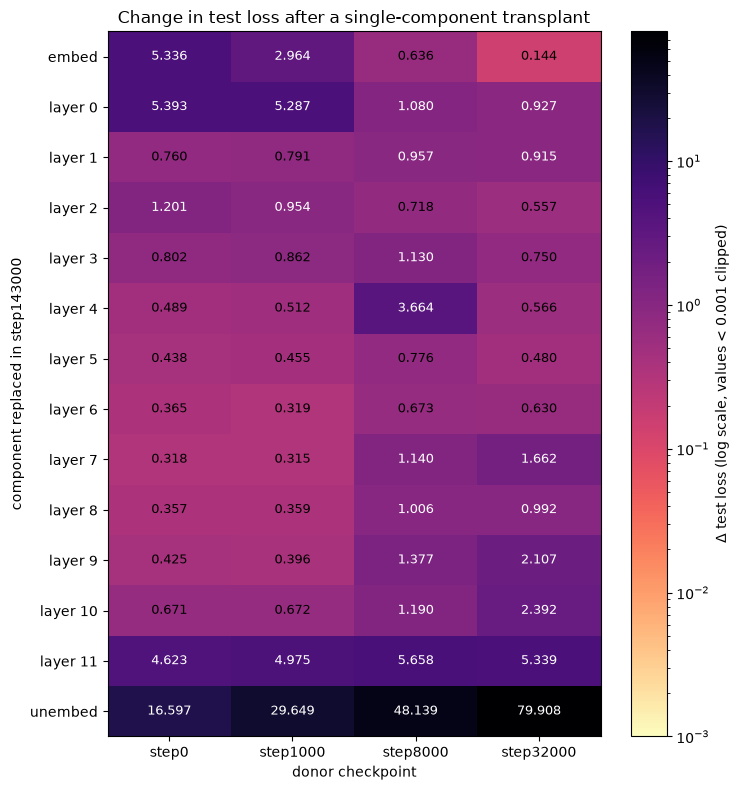

Δ test loss (rows: component, columns: donor)
                step0   step1000   step8000  step32000
     embed     5.3358     2.9642     0.6364     0.1440
   layer 0     5.3930     5.2868     1.0798     0.9268
   layer 1     0.7600     0.7908     0.9566     0.9153
   layer 2     1.2014     0.9544     0.7183     0.5573
   layer 3     0.8025     0.8624     1.1300     0.7502
   layer 4     0.4888     0.5123     3.6635     0.5663
   layer 5     0.4376     0.4549     0.7764     0.4802
   layer 6     0.3650     0.3189     0.6732     0.6297
   layer 7     0.3183     0.3147     1.1402     1.6625
   layer 8     0.3565     0.3594     1.0063     0.9915
   layer 9     0.4254     0.3964     1.3772     2.1068
  layer 10     0.6715     0.6718     1.1897     2.3923
  layer 11     4.6227     4.9755     5.6576     5.3387
   unembed    16.5973    29.6494    48.1389    79.9082


In [9]:
floor = 1e-3
fig, ax = plt.subplots(figsize=(7.5, 8))
im = ax.imshow(np.clip(delta, floor, None), cmap="magma_r", norm=LogNorm(vmin=floor, vmax=delta.max()), aspect="auto")
for i in range(len(components)):
    for j in range(len(donors)):
        v = delta[i, j]
        shade = np.log(max(v, floor) / floor) / np.log(delta.max() / floor)
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9, color="white" if shade > 0.6 else "black")
ax.set_xticks(range(len(donors)))
ax.set_xticklabels(donors)
ax.set_yticks(range(len(components)))
ax.set_yticklabels(components)
ax.set_xlabel("donor checkpoint")
ax.set_ylabel("component replaced in step143000")
ax.set_title("Change in test loss after a single-component transplant")
fig.colorbar(im, ax=ax, label=f"Δ test loss (log scale, values < {floor} clipped)")
fig.tight_layout()
plt.show()

print("Δ test loss (rows: component, columns: donor)")
print(f"{'':>10s}" + "".join(f"{d:>11s}" for d in donors))
for i, name in enumerate(components):
    print(f"{name:>10s}" + "".join(f"{delta[i, j]:11.4f}" for j in range(len(donors))))

An additional plot: how far each donor component's weights are from the final model's, as a relative distance ‖W_donor − W_final‖ / ‖W_final‖. This helps explain which transplants are cheap.

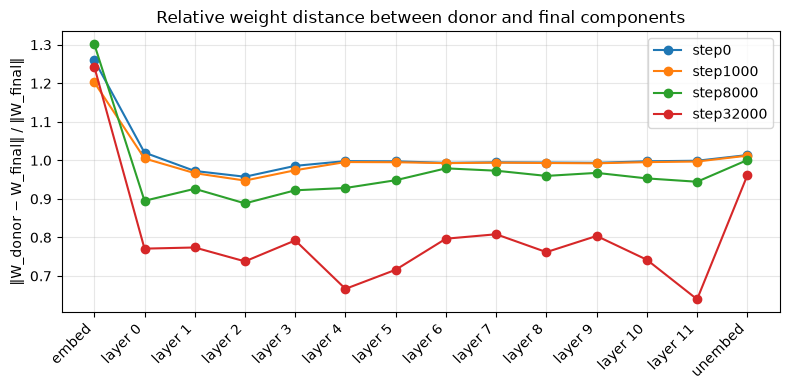

relative weight distance (rows: component, columns: donor)
                step0   step1000   step8000  step32000
     embed     1.2600     1.2027     1.3018     1.2432
   layer 0     1.0202     1.0049     0.8950     0.7708
   layer 1     0.9724     0.9668     0.9261     0.7738
   layer 2     0.9575     0.9475     0.8883     0.7377
   layer 3     0.9857     0.9743     0.9222     0.7922
   layer 4     0.9980     0.9956     0.9283     0.6664
   layer 5     0.9975     0.9952     0.9484     0.7160
   layer 6     0.9935     0.9928     0.9792     0.7966
   layer 7     0.9949     0.9940     0.9731     0.8081
   layer 8     0.9943     0.9931     0.9596     0.7618
   layer 9     0.9936     0.9924     0.9675     0.8037
  layer 10     0.9975     0.9954     0.9531     0.7419
  layer 11     0.9990     0.9969     0.9444     0.6393
   unembed     1.0137     1.0122     1.0008     0.9612


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for j, rev in enumerate(donors):
    ax.plot(range(len(components)), rel_dist[:, j], marker="o", label=rev)
ax.set_xticks(range(len(components)))
ax.set_xticklabels(components, rotation=45, ha="right")
ax.set_ylabel("‖W_donor − W_final‖ / ‖W_final‖")
ax.set_title("Relative weight distance between donor and final components")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print("relative weight distance (rows: component, columns: donor)")
print(f"{'':>10s}" + "".join(f"{d:>11s}" for d in donors))
for i, name in enumerate(components):
    print(f"{name:>10s}" + "".join(f"{rel_dist[i, j]:11.4f}" for j in range(len(donors))))

Additional experiment 1: is a random (step0) layer just a skipped layer? Pythia layers add `attn(LN(x)) + mlp(LN(x))` to the residual stream, so zeroing the two output projections (`attention.dense`, `mlp.dense_4h_to_h`) removes a layer entirely. I compare that loss change with the transplants, and measure how large an update ‖h_out − h_in‖ each transplanted layer writes into the final model's residual stream (mean over the first 512 tokens).

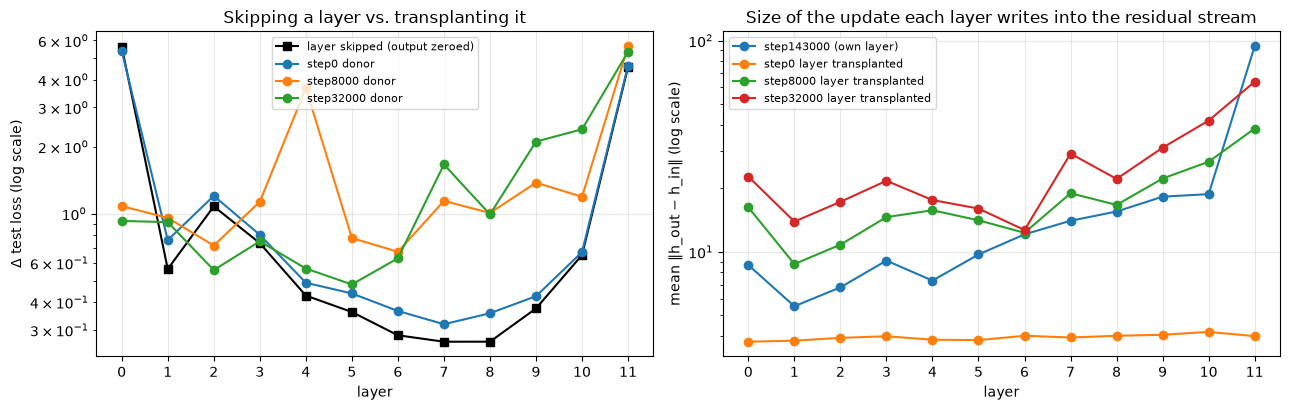

Δ test loss: layer skipped / step0 donor / step32000 donor | update norm ‖h_out − h_in‖: own layer / step0 / step8000 / step32000 donor
layer   skip Δ  step0 Δ  s32000 Δ |        own     step0  step8000 step32000
    0   5.6239   5.3930    0.9268 |       8.67      3.76     16.25     22.72
    1   0.5636   0.7600    0.9153 |       5.53      3.80      8.76     13.91
    2   1.0775   1.2014    0.5573 |       6.79      3.92     10.82     17.24
    3   0.7366   0.8025    0.7502 |       9.09      3.99     14.60     21.69
    4   0.4281   0.4888    0.5663 |       7.31      3.84     15.74     17.59
    5   0.3612   0.4376    0.4802 |       9.72      3.82     14.10     16.03
    6   0.2838   0.3650    0.6297 |      12.10      4.01     12.31     12.69
    7   0.2655   0.3183    1.6625 |      14.04      3.93     18.93     29.17
    8   0.2656   0.3565    0.9915 |      15.52      4.01     16.68     22.13
    9   0.3746   0.4254    2.1068 |      18.24      4.05     22.23     31.12
   10   0.6513   


test loss after undoing all edits: 3.3119 (intact 3.3119)


In [11]:
def layer_update_norm(model, i):
    captured = {}

    def hook(module, args, kwargs, output):
        h_in = args[0] if args else kwargs["hidden_states"]
        h_out = output[0] if isinstance(output, tuple) else output
        captured["norm"] = (h_out - h_in).norm(dim=-1).mean().item()

    handle = model.gpt_neox.layers[i].register_forward_hook(hook, with_kwargs=True)
    model(chunks[0][None])
    handle.remove()
    return captured["norm"]


layer_ids = list(range(12))
skip_delta = []
for i in layer_ids:
    layer = final.gpt_neox.layers[i]
    original = {k: v.clone() for k, v in layer.state_dict().items()}
    for linear in (layer.attention.dense, layer.mlp.dense_4h_to_h):
        linear.weight.zero_()
        linear.bias.zero_()
    skip_delta.append(test_loss(final) - base)
    layer.load_state_dict(original)

update = {"own": [layer_update_norm(final, i) for i in layer_ids]}
for rev in ["step0", "step8000", "step32000"]:
    donor = load(rev)
    norms = []
    for i in layer_ids:
        target = final.gpt_neox.layers[i]
        original = {k: v.clone() for k, v in target.state_dict().items()}
        target.load_state_dict(donor.gpt_neox.layers[i].state_dict())
        norms.append(layer_update_norm(final, i))
        target.load_state_dict(original)
    update[rev] = norms
    del donor
    gc.collect()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(layer_ids, skip_delta, marker="s", color="black", label="layer skipped (output zeroed)")
for rev in ["step0", "step8000", "step32000"]:
    axes[0].plot(layer_ids, delta[1:13, donors.index(rev)], marker="o", label=f"{rev} donor")
axes[0].set_yscale("log")
axes[0].set_xlabel("layer")
axes[0].set_ylabel("Δ test loss (log scale)")
axes[0].set_title("Skipping a layer vs. transplanting it")
axes[0].legend(fontsize=8)
for name, norms in update.items():
    axes[1].plot(layer_ids, norms, marker="o", label="step143000 (own layer)" if name == "own" else f"{name} layer transplanted")
axes[1].set_yscale("log")
axes[1].set_xlabel("layer")
axes[1].set_ylabel("mean ‖h_out − h_in‖ (log scale)")
axes[1].set_title("Size of the update each layer writes into the residual stream")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xticks(layer_ids)
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

print("Δ test loss: layer skipped / step0 donor / step32000 donor | update norm ‖h_out − h_in‖: own layer / step0 / step8000 / step32000 donor")
print(f"{'layer':>5s} {'skip Δ':>8s} {'step0 Δ':>8s} {'s32000 Δ':>9s} | " + "".join(f"{k:>10s}" for k in update))
for i in layer_ids:
    print(f"{i:>5d} {skip_delta[i]:8.4f} {delta[i + 1, 0]:8.4f} {delta[i + 1, 3]:9.4f} | "
          + "".join(f"{update[k][i]:10.2f}" for k in update))
print(f"\ntest loss after undoing all edits: {test_loss(final):.4f} (intact {base:.4f})")

Additional experiment 2: why does a later unembedding hurt more? I compare the size of each donor's unembedding matrix with the final one, and how confident the final model becomes with each donor unembedding (mean probability of its top-1 prediction over the test set).

In [12]:
unembed = final.get_output_embeddings()
original = {k: v.clone() for k, v in unembed.state_dict().items()}
print(f"uniform prediction over {len(tok)} tokens would give loss log(V) = {np.log(len(tok)):.2f}; intact loss {base:.4f}\n")
print(f"{'unembedding':>12s} {'‖W_U‖_F':>9s} {'Δ test loss':>12s} {'mean top-1 prob':>16s} {'top-1 accuracy':>15s}")


def confidence_and_accuracy(model):
    conf, correct = 0.0, 0
    for c in chunks:
        p = model(c[None]).logits[0, :-1].softmax(-1)
        conf += p.max(-1).values.sum().item()
        correct += (p.argmax(-1) == c[1:]).sum().item()
    return conf / n_targets, correct / n_targets


conf, acc_final = confidence_and_accuracy(final)
print(f"{'step143000':>12s} {original['weight'].norm():9.1f} {0.0:12.4f} {conf:16.4f} {acc_final:15.4f}")
for j, rev in enumerate(donors):
    donor = load(rev)
    W = donor.get_output_embeddings().state_dict()
    unembed.load_state_dict(W)
    conf, acc_t = confidence_and_accuracy(final)
    unembed.load_state_dict(original)
    print(f"{rev:>12s} {W['weight'].norm():9.1f} {delta[-1, j]:12.4f} {conf:16.4f} {acc_t:15.4f}")
    del donor
    gc.collect()
print(f"\ntest loss after undoing all edits: {test_loss(final):.4f} (intact {base:.4f})")

uniform prediction over 50277 tokens would give loss log(V) = 10.83; intact loss 3.3119

 unembedding   ‖W_U‖_F  Δ test loss  mean top-1 prob  top-1 accuracy


  step143000     811.3       0.0000           0.3711          0.3567


       step0     141.4      16.5973           0.1609          0.0243


    step1000     209.6      29.6494           0.5042          0.0007


    step8000     294.0      48.1389           0.8397          0.0007


   step32000     285.2      79.9082           0.7624          0.0000



test loss after undoing all edits: 3.3119 (intact 3.3119)


**Which components can the model lose, and which are irreplaceable?**

- **Losable: most middle layers (1–10).** Replacing them with random step0 weights raises the test loss (intact 3.312) by only 0.32–1.20 (for example layer 7: +0.318, layer 6: +0.365, layer 5: +0.438). Additional experiment 1 shows why: a random layer behaves like a *skipped* layer. Zeroing the layer's output costs almost the same at every layer (layer 7: +0.266 skipped vs. +0.318 random; layer 4: +0.428 vs. +0.489), because the step0 layer writes only a small update into the residual stream (norm ≈ 4, vs. 7–19 for the model's own layers 4–10). The residual connection lets the rest of the network work around a missing middle layer.
- **Irreplaceable: layer 0, layer 11 and the unembedding.** Random weights cost +5.39 (layer 0), +4.62 (layer 11) and +16.60 (unembedding), and skipping layer 0 or 11 costs about as much (+5.62, +4.56). Layer 11 cannot be rescued by any donor (+4.62 to +5.66), and the unembedding is far worse with every donor (+16.6 to +79.9). The embedding is also expensive with early donors (+5.34 from step0, +2.96 from step1000) but nearly replaceable from step32000 (+0.144).

**Does a later donor always hurt less? No.** Only the embedding (5.34 → 2.96 → 0.64 → 0.14) and layer 0 (5.39 → 5.29 → 1.08 → 0.93) improve steadily with later donors. For many layers the *random* donor hurts least:

- **Middle and late layers.** Layer 7 costs +0.318 from step0 but +1.140 from step8000 and +1.662 from step32000; layers 9 and 10 cost +0.425 and +0.671 from step0 but +2.107 and +2.392 from step32000. Layer 4 from step8000 is a striking outlier at +3.664, vs. +0.489 from step0. The second panel of experiment 1 explains this: a trained donor layer writes a *large* update that the final model's other layers no longer understand (layer 10 from step32000 writes ‖Δh‖ = 41.8, vs. 18.8 for its own layer 10; layer 7: 29.2 vs. 14.0). The weight-distance plot shows that even step32000 layers are 64–81% of a full weight-norm away from the final ones. A random layer adds little noise that later layers can ignore, while a trained-but-outdated layer writes confident, structured signals in the wrong "language".
- **The unembedding** gets dramatically worse with later donors (+16.6, +29.6, +48.1, +79.9). Experiment 2 shows why: with any donor unembedding the top-1 accuracy is about 0 (0.024 for step0, ≤ 0.001 for the others), but the model's confidence rises from 0.16 (step0) to 0.50, 0.84 and 0.76. A later unembedding has sharper token directions, but they do not line up with the final model's residual stream, so the model becomes *confidently wrong*, and cross-entropy punishes confident mistakes heavily. Every donor's loss is far above the 10.83 of a uniform guess.

Overall, the layers of the final model are not compatible with their younger selves: components co-adapt during training, so a component is only useful together with the parts it was trained with. The input end (embedding, layer 0) stabilizes earliest, while the late layers and the unembedding keep changing their shared "language" until the end of training.